# Student Performance Analysis & Prediction using Machine Learning

**Name:** Khadija Anwer Hussain  
**Course:** Data Science  
**Tools:** Python 3, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn (Jupyter Notebook)

## Project Overview

**Problem:** Which factors affect how well students perform in exams, and can a machine learning model predict a student's result?

**Dataset:** *Students Performance in Exams* (Kaggle) with 1000 students and these columns: `gender`, `race/ethnicity`, `parental level of education`, `lunch`, `test preparation course`, `math score`, `reading score`, `writing score`.

**What I do in this project:**
1. Load and check the data (cleaning)
2. Explore it with charts (EDA)
3. **Regression:** predict a student's *math score* (Linear Regression vs Random Forest)
4. **Classification:** predict if a student will *Pass or Fail* (Logistic Regression vs Random Forest)
5. Compare the models and write the conclusion

## Step 1: Import Libraries

- **pandas / numpy** for data handling
- **matplotlib / seaborn** for charts
- **scikit-learn** for machine learning models and evaluation

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42      # fixed seed -> same results every time the notebook is run
print('Libraries imported.')

Libraries imported.


## Step 2: Load the Dataset

I load the file `StudentsPerformance.csv` (the *Students Performance in Exams* dataset from Kaggle) with `pd.read_csv()`. The file must be in the same folder as this notebook.

In [2]:
df = pd.read_csv('StudentsPerformance.csv')
print('Shape (rows, columns):', df.shape)
df.head()

Shape (rows, columns): (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,male,group A,bachelor's degree,free/reduced,completed,60,49,52
1,female,group C,some college,standard,none,64,52,61
2,male,group B,master's degree,standard,completed,78,73,79
3,male,group B,associate's degree,free/reduced,none,55,54,48
4,female,group D,some high school,standard,none,59,62,76


## Step 3:  Data Cleaning

Before any chart or model I check the basics: column types, missing values and duplicates. I also rename the columns to simple lowercase names with underscores (e.g. `math score` becomes `math_score`) because they are easier to type and safer in code.

In [3]:
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(' ', '_').str.replace('/', '_'))
print(list(df.columns))
print()
df.info()

['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score']

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 103.3 KB


In [4]:
orig_rows, orig_cols = df.shape      # remember the original size before adding new columns

print('Missing values per column:')
print(df.isnull().sum())
print()
print('Duplicate rows:', df.duplicated().sum())
df.describe()

Missing values per column:
gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

Duplicate rows: 0


,math_score,reading_score,writing_score
count,1000.000000,1000.000000,1000.000000
mean,66.523000,66.364000,67.431000
std,14.546583,14.591656,15.222186
min,19.000000,5.000000,8.000000
25%,57.000000,57.000000,58.000000
50%,66.000000,67.000000,68.000000
75%,77.000000,76.000000,78.000000
max,100.000000,100.000000,100.000000


**Observations:**
- The dataset has **1000 rows and 8 columns**.
- Missing values: **0**. Duplicate rows: **0**. So the data is already clean and no rows need to be dropped or filled.
- 5 columns are categories (text) and 3 columns (`math_score`, `reading_score`, `writing_score`) are numbers from 0 to 100.

### Create two new columns

- `average_score`: the mean of the three subject scores.
- `result`: **Pass** if `average_score` is 60 or more, otherwise **Fail**. (The 60 mark is my own choice for this project.) This is the target for the classification model later.

In [5]:
df['average_score'] = df[['math_score', 'reading_score', 'writing_score']].mean(axis=1).round(2)
df['result'] = np.where(df['average_score'] >= 60, 'Pass', 'Fail')

print(df['result'].value_counts())
print()
print((df['result'].value_counts(normalize=True) * 100).round(1), '(%)')
df.head()

result
Pass    704
Fail    296
Name: count, dtype: int64

result
Pass    70.4
Fail    29.6
Name: proportion, dtype: float64 (%)


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,average_score,result
0,male,group A,bachelor's degree,free/reduced,completed,60,49,52,53.67,Fail
1,female,group C,some college,standard,none,64,52,61,59.00,Fail
2,male,group B,master's degree,standard,completed,78,73,79,76.67,Pass
3,male,group B,associate's degree,free/reduced,none,55,54,48,52.33,Fail
4,female,group D,some high school,standard,none,59,62,76,65.67,Pass


### Additional Data Cleaning Checks

The data has no missing values and no duplicate rows (checked above), but data cleaning also means checking for hidden problems. I check three more things:
1. **Text columns:** extra spaces or inconsistent spellings (e.g. "Male", "male ", "MALE").
2. **Score range:** scores must be between 0 and 100.
3. **Outliers:** unusually low or high scores.

In [6]:
# 1) Text columns: remove extra spaces and list the unique values
text_cols = ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']

n_stripped = 0
for col in text_cols:
    cleaned = df[col].str.strip()
    n_stripped += int((cleaned != df[col]).sum())     # how many values needed fixing
    df[col] = cleaned
    print(col, '->', sorted(df[col].unique()))

print()
print('Values fixed by removing extra spaces:', n_stripped)

gender -> ['female', 'male']
race_ethnicity -> ['group A', 'group B', 'group C', 'group D', 'group E']
parental_level_of_education -> ["associate's degree", "bachelor's degree", 'high school', "master's degree", 'some college', 'some high school']
lunch -> ['free/reduced', 'standard']
test_preparation_course -> ['completed', 'none']

Values fixed by removing extra spaces: 0


In [7]:
# 2) Score range check: every score must be between 0 and 100
score_cols = ['math_score', 'reading_score', 'writing_score']

print(df[score_cols].agg(['min', 'max']))
print()
print('Scores below 0:  ', (df[score_cols] < 0).sum().sum())
print('Scores above 100:', (df[score_cols] > 100).sum().sum())

     math_score  reading_score  writing_score
min          19              5              8
max         100            100            100

Scores below 0:   0
Scores above 100: 0


               lower_limit  upper_limit  low_outliers  high_outliers
column                                                              
math_score            27.0        107.0             5              0
reading_score         28.5        104.5             7              0
writing_score         28.0        108.0            10              0


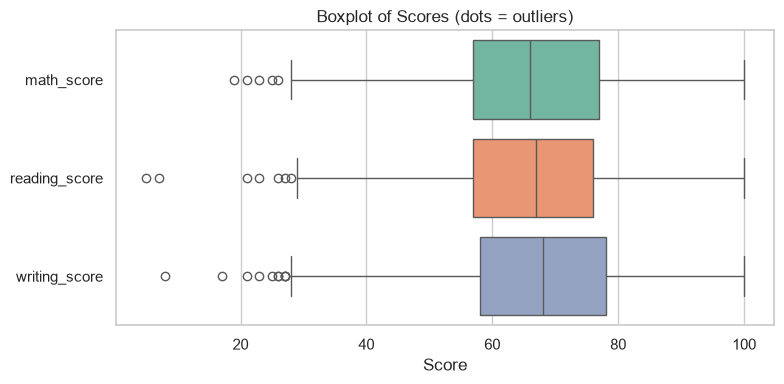

In [8]:
# 3) Outliers using the IQR rule (a value is an outlier if it is far below Q1 or far above Q3)
rows = []
for col in score_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_low = int((df[col] < low).sum())
    n_high = int((df[col] > high).sum())
    rows.append({'column': col, 'lower_limit': round(low, 1), 'upper_limit': round(high, 1),
                 'low_outliers': n_low, 'high_outliers': n_high})

outlier_table = pd.DataFrame(rows).set_index('column')
print(outlier_table)

plt.figure(figsize=(8, 4))
sns.boxplot(data=df[score_cols], orient='h', palette='Set2')
plt.title('Boxplot of Scores (dots = outliers)')
plt.xlabel('Score')
plt.tight_layout()
plt.show()

**Findings:**
- **Text columns:** 0 values needed fixing. There are no extra spaces and no inconsistent spellings (gender has 2 values, race/ethnicity 5, parents' education 6, lunch 2, test preparation 2).
- **Score range:** all scores are between 0 and 100 (lowest values: math 19, reading 5, writing 8).
- **Outliers:** the IQR rule flags **5** math, **7** reading and **10** writing scores (all unusually low scores). I decided to **keep them**, because they are real students with real low marks, not data entry errors. Removing them would also hide the students who struggle most, which are exactly the students this analysis is about.

### Data Cleaning Summary

| Check | Result | Action |
|---|---|---|
| Missing values | 0 | None needed |
| Duplicate rows | 0 | None needed |
| Column names | Spaces and `/` in names | Renamed to lowercase with underscores |
| Text columns | 0 values with extra spaces | Stripped spaces |
| Score range (0–100) | Valid | None needed |
| Outliers | Low scores only | Kept (real data) |
| New columns | N/A | Created `average_score` and `result` |

## Step 4: Exploratory Data Analysis (EDA)

Charts help me see patterns before building models.

### 4.1 How are the scores distributed?

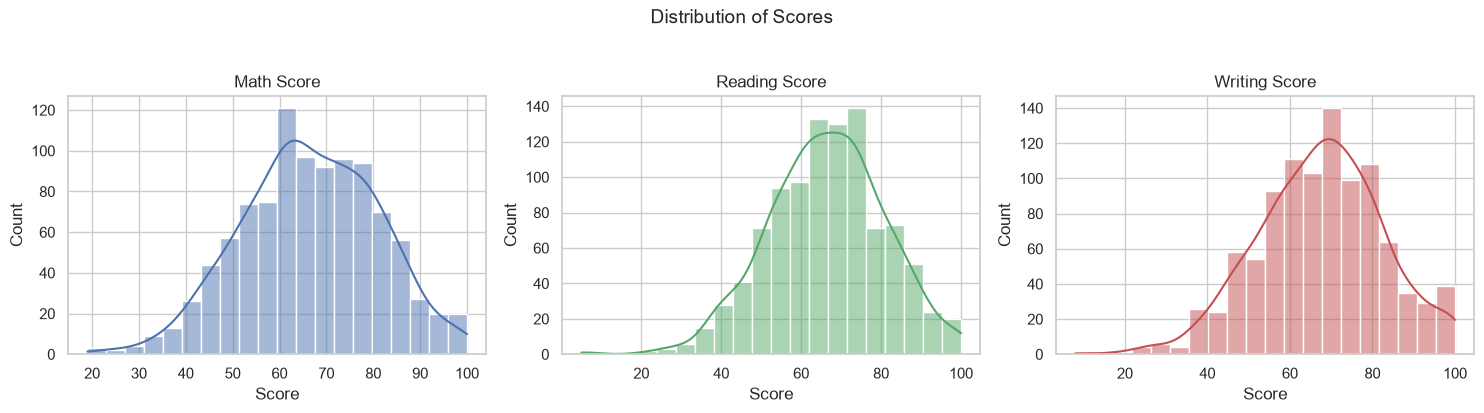

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, color in zip(axes, ['math_score', 'reading_score', 'writing_score'],
                          ['#4C72B0', '#55A868', '#C44E52']):
    sns.histplot(df[col], bins=20, kde=True, color=color, ax=ax)
    ax.set_title(col.replace('_', ' ').title())
    ax.set_xlabel('Score')
plt.suptitle('Distribution of Scores', y=1.03, fontsize=14)
plt.tight_layout()
plt.show()

All three scores are spread around the middle (roughly bell-shaped) with a few very low scores. The average math score is **66.5**, reading **66.4** and writing **67.4**.

### 4.2 Do lunch type and the test preparation course matter?

Average score by test preparation course:
 test_preparation_course
completed    70.5
none         64.9
Name: average_score, dtype: float64 

Average score by lunch type:
 lunch
free/reduced    62.5
standard        69.1
Name: average_score, dtype: float64


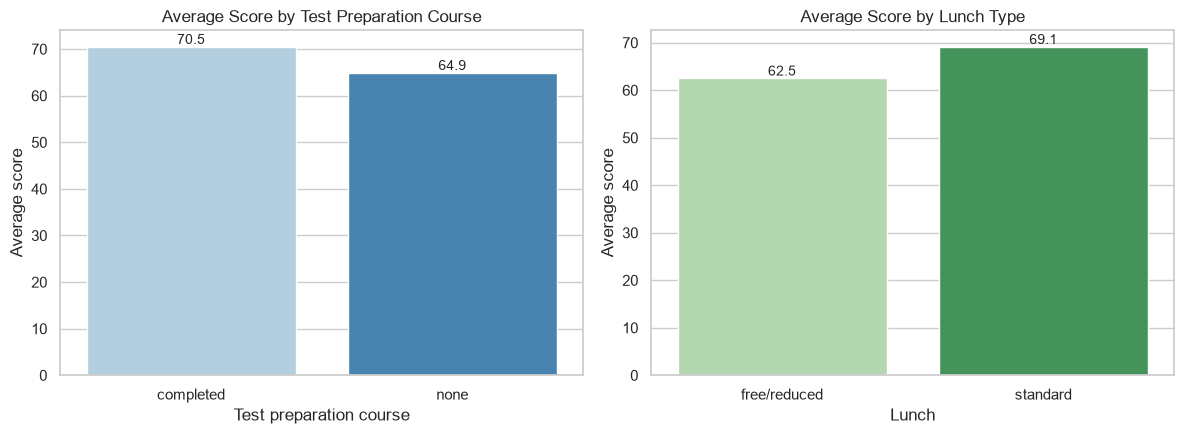

In [10]:
prep_avg = df.groupby('test_preparation_course')['average_score'].mean().round(1)
lunch_avg = df.groupby('lunch')['average_score'].mean().round(1)
print('Average score by test preparation course:\n', prep_avg, '\n')
print('Average score by lunch type:\n', lunch_avg)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(x='test_preparation_course', y='average_score', data=df, ax=axes[0],
            palette='Blues', errorbar=None)
axes[0].set_title('Average Score by Test Preparation Course')
axes[0].set_xlabel('Test preparation course'); axes[0].set_ylabel('Average score')
sns.barplot(x='lunch', y='average_score', data=df, ax=axes[1], palette='Greens', errorbar=None)
axes[1].set_title('Average Score by Lunch Type')
axes[1].set_xlabel('Lunch'); axes[1].set_ylabel('Average score')
for ax in axes:
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1f}', (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.show()

Students who **completed the test preparation course** have an average of **70.5**, compared to **64.9** for those who did not. Students with a **standard lunch** average **69.1**, compared to **62.5** for free/reduced lunch.

### 4.3 Does the parents' education level matter?

parental_level_of_education
some high school      65.0
high school           63.9
some college          66.1
associate's degree    68.0
bachelor's degree     70.6
master's degree       72.9
Name: average_score, dtype: float64


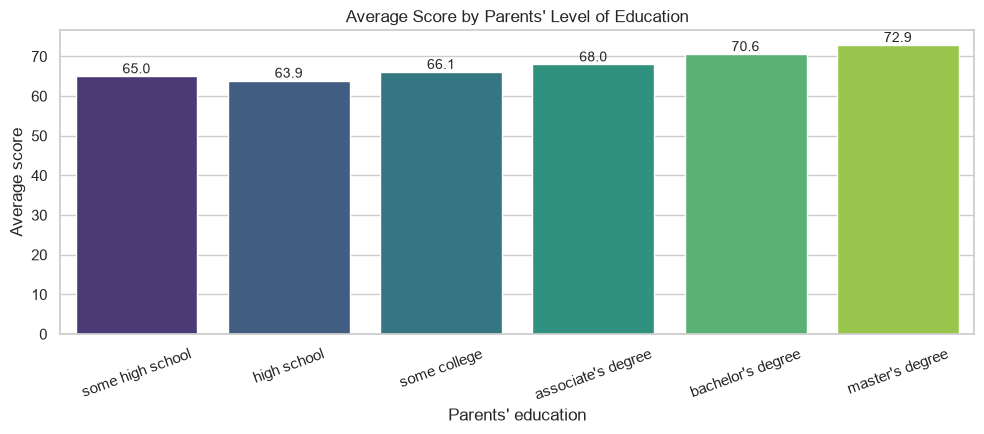

In [11]:
order = ["some high school", "high school", "some college",
         "associate's degree", "bachelor's degree", "master's degree"]
edu_avg = df.groupby('parental_level_of_education')['average_score'].mean().reindex(order).round(1)
print(edu_avg)

plt.figure(figsize=(10, 4.5))
ax = sns.barplot(x=edu_avg.index, y=edu_avg.values, palette='viridis')
for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=10)
plt.title("Average Score by Parents' Level of Education")
plt.xlabel("Parents' education"); plt.ylabel('Average score')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

The lowest average (**63.9**) belongs to students whose parents' education is **"high school"** and the highest (**72.9**) to **"master's degree"**. In general, students with more educated parents score higher.

### 4.4 Gender comparison in each subject

        math_score  reading_score  writing_score
gender                                          
female        64.0           68.9           72.0
male          69.3           63.6           62.4


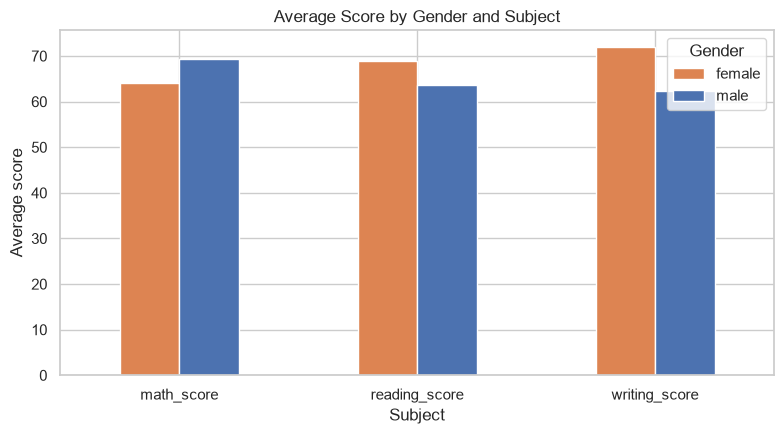

In [12]:
gender_avg = df.groupby('gender')[['math_score', 'reading_score', 'writing_score']].mean().round(1)
print(gender_avg)

gender_avg.T.plot(kind='bar', figsize=(8, 4.5), color=['#DD8452', '#4C72B0'])
plt.title('Average Score by Gender and Subject')
plt.ylabel('Average score'); plt.xlabel('Subject')
plt.xticks(rotation=0)
plt.legend(title='Gender')
plt.tight_layout()
plt.show()

### 4.5 How are the three scores related? (Correlation)

Correlation is a number between -1 and +1. Close to **+1** means that when one score goes up, the other goes up too.

               math_score  reading_score  writing_score
math_score           1.00           0.76           0.71
reading_score        0.76           1.00           0.83
writing_score        0.71           0.83           1.00


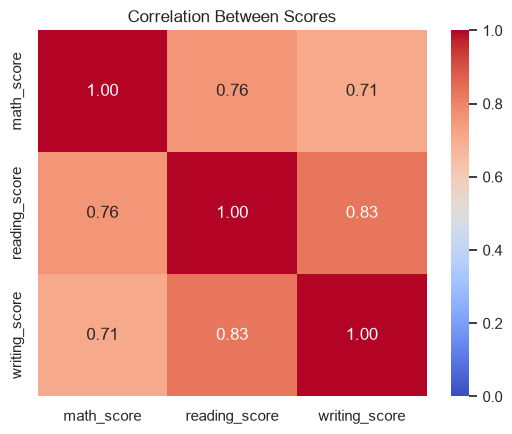

In [13]:
corr = df[['math_score', 'reading_score', 'writing_score']].corr().round(2)
print(corr)

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=0, vmax=1, fmt='.2f')
plt.title('Correlation Between Scores')
plt.tight_layout()
plt.show()

The scores are strongly related to each other (for example math and reading: **0.76**). A student who does well in one subject usually does well in the others. This is why reading and writing scores will help to predict the math score in the regression model.

## Step 5: Machine Learning Model 1 — Regression (Predict the Math Score)

**Regression** predicts a *number*. Here the target is `math_score`.

**Features (inputs):** gender, race/ethnicity, parents' education, lunch, test preparation course, reading score and writing score.

**Important:** I do **not** use `average_score` or `result` as inputs, because they are calculated *from* the math score. That would be **data leakage** (the model would "see" the answer).

**Preparation steps:**
1. **One-hot encoding** (`pd.get_dummies`): models only understand numbers, so a text column like `lunch` becomes a 0/1 column.
2. **Train/test split (80% / 20%):** the model learns from the training part and is tested on the 20% of students it has never seen. This shows how it would perform on new students.

In [14]:
X_raw = df.drop(columns=['math_score', 'average_score', 'result'])
y_reg = df['math_score']

X_reg = pd.get_dummies(X_raw, drop_first=True)      # text columns -> 0/1 columns
print('Features after encoding:', X_reg.shape[1])

X_train, X_test, y_train, y_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE)
print('Training rows:', X_train.shape[0], '| Testing rows:', X_test.shape[0])
X_reg.head()

Features after encoding: 14
Training rows: 800 | Testing rows: 200


,reading_score,writing_score,gender_male,race_ethnicity_group B,race_ethnicity_group C,race_ethnicity_group D,race_ethnicity_group E,parental_level_of_education_bachelor's degree,parental_level_of_education_high school,parental_level_of_education_master's degree,parental_level_of_education_some college,parental_level_of_education_some high school,lunch_standard,test_preparation_course_none
0,49,52,True,False,False,False,False,True,False,False,False,False,False,False
1,52,61,False,False,True,False,False,False,False,False,True,False,True,True
2,73,79,True,True,False,False,False,False,False,True,False,False,True,False
3,54,48,True,True,False,False,False,False,False,False,False,False,False,True
4,62,76,False,False,False,True,False,False,False,False,False,True,True,True


### Train two models

- **Linear Regression:** draws the best straight-line relationship between inputs and the score. Simple and easy to explain.
- **Random Forest Regressor:** builds many decision trees and averages them. It can capture more complex patterns.

**Metrics used:**
- **R²:** how much of the variation in math scores the model explains (1.0 is perfect, 0 is no better than guessing the average).
- **MAE:** the average mistake in score points (lower is better).
- **RMSE:** like MAE but punishes big mistakes more (lower is better).

In [15]:
reg_models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE),
}

reg_rows, reg_preds = {}, {}
for name, model in reg_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    reg_preds[name] = pred
    reg_rows[name] = {
        'R2': r2_score(y_test, pred),
        'MAE': mean_absolute_error(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
    }

reg_results = pd.DataFrame(reg_rows).T.round(3)
reg_results

,R2,MAE,RMSE
Linear Regression,0.761,6.264,7.719
Random Forest,0.729,6.582,8.216


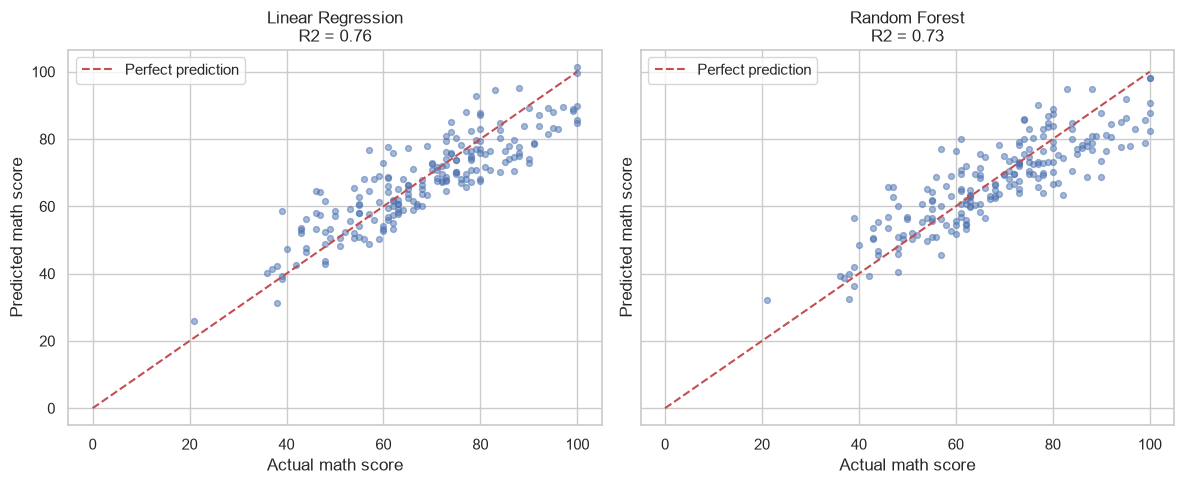

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, (name, pred) in zip(axes, reg_preds.items()):
    ax.scatter(y_test, pred, alpha=0.5, s=18)
    ax.plot([0, 100], [0, 100], 'r--', label='Perfect prediction')
    ax.set_title(f'{name}\nR2 = {reg_results.loc[name, "R2"]:.2f}')
    ax.set_xlabel('Actual math score'); ax.set_ylabel('Predicted math score')
    ax.legend()
plt.tight_layout()
plt.show()

Each dot is one student from the test set. The closer the dots are to the red dashed line, the better the prediction.

**Result:** **Linear Regression** performed best with an **R² of 0.76** and an average error of about **6.3 points**. The simple Linear Regression is at least as good as the more complex Random Forest here, so the simpler model is the better choice.

### Which inputs matter most?

The Random Forest can tell how important each feature was for its predictions.

reading_score                               0.596
writing_score                               0.187
gender_male                                 0.105
test_preparation_course_none                0.013
lunch_standard                              0.013
parental_level_of_education_some college    0.011
race_ethnicity_group D                      0.011
race_ethnicity_group C                      0.010
dtype: float64


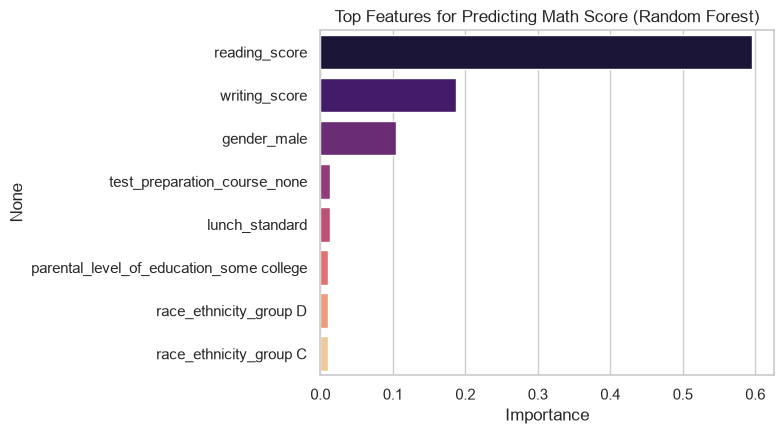

In [17]:
importances = (pd.Series(reg_models['Random Forest'].feature_importances_, index=X_reg.columns)
               .sort_values(ascending=False).head(8))
print(importances.round(3))

plt.figure(figsize=(8, 4.5))
sns.barplot(x=importances.values, y=importances.index, palette='magma')
plt.title('Top Features for Predicting Math Score (Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

The most important feature is **`reading_score`** (importance 0.60), followed by **`writing_score`** (0.19) and **`gender_male`** (0.11). This matches the correlation heatmap: reading and writing scores are the strongest clues for the math score.

## Step 6: Machine Learning Model 2 — Classification (Predict Pass or Fail)

**Classification** predicts a *category*. Here the target is `result` (**Pass** = 1, **Fail** = 0).

**Features (inputs):** only background information — gender, race/ethnicity, parents' education, lunch and test preparation course. I do **not** use the scores here, because `result` is calculated from the scores (again, that would be data leakage). This makes the question more interesting: *can we tell from a student's background whether they are likely to pass?*

For the split I use `stratify=y` so that the Pass/Fail share is the same in the training and test sets.

In [18]:
X_clf_raw = df[['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']]
y_clf = (df['result'] == 'Pass').astype(int)

X_clf = pd.get_dummies(X_clf_raw, drop_first=True)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf)

baseline = max(yc_test.mean(), 1 - yc_test.mean())
print('Training rows:', Xc_train.shape[0], '| Testing rows:', Xc_test.shape[0])
print(f'Baseline accuracy (always guess the most common result): {baseline:.3f}')

Training rows: 800 | Testing rows: 200
Baseline accuracy (always guess the most common result): 0.705


### Baseline

If a model simply guessed "Pass" for every student, it would already be right **70.5%** of the time. A useful model must beat this number, so I use it as the **baseline** to compare against.

### Train two models

- **Logistic Regression:** despite its name, it is a classification model. It calculates the probability of "Pass" for a student.
- **Random Forest Classifier:** many decision trees vote on the answer. I limit `max_depth=5` so the trees stay simple and do not memorise the training data (overfitting).

In [19]:
clf_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=5, random_state=RANDOM_STATE),
}

clf_rows, clf_preds = {}, {}
for name, model in clf_models.items():
    model.fit(Xc_train, yc_train)
    pred = model.predict(Xc_test)
    clf_preds[name] = pred
    clf_rows[name] = {
        'Train accuracy': accuracy_score(yc_train, model.predict(Xc_train)),
        'Test accuracy': accuracy_score(yc_test, pred),
    }

clf_results = pd.DataFrame(clf_rows).T.round(3)
clf_results['Baseline'] = round(baseline, 3)
clf_results

,Train accuracy,Test accuracy,Baseline
Logistic Regression,0.726,0.71,0.705
Random Forest,0.729,0.68,0.705


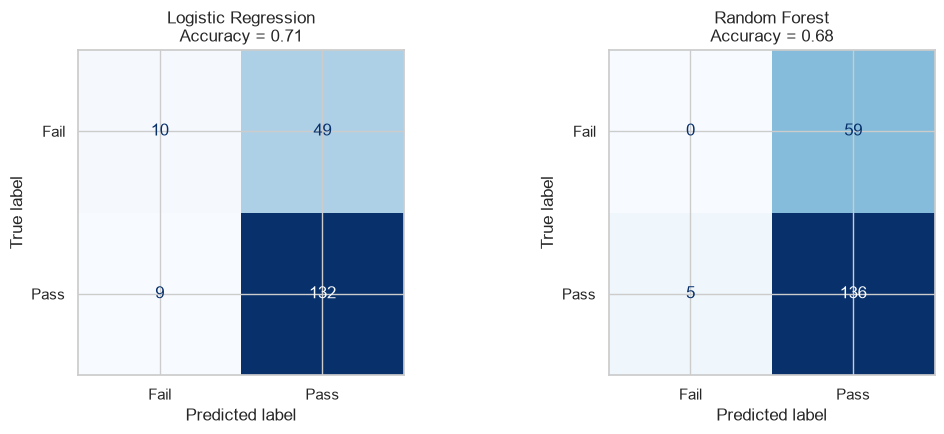

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pred) in zip(axes, clf_preds.items()):
    cm = confusion_matrix(yc_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=['Fail', 'Pass']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{name}\nAccuracy = {accuracy_score(yc_test, pred):.2f}')
plt.tight_layout()
plt.show()

**How to read a confusion matrix:** rows are the *actual* result, columns are the *predicted* result. The numbers on the diagonal (top-left and bottom-right) are correct predictions; the other two are mistakes.

**Result:** the best classifier is **Logistic Regression** with a test accuracy of **71.0%**, compared with the baseline of **70.5%**. It beats the baseline only slightly, so background information alone is a weak predictor of the result.

The Random Forest (68.0%) is even below the baseline: its confusion matrix shows that it predicted "Pass" for almost every student and did not find a single failing student. Its accuracy looks acceptable only because most students in the data pass.

In [21]:
best_clf = clf_results['Test accuracy'].idxmax()
print('Detailed report for the best model:', best_clf)
print()
print(classification_report(yc_test, clf_preds[best_clf], target_names=['Fail', 'Pass']))

Detailed report for the best model: Logistic Regression

              precision    recall  f1-score   support

        Fail       0.53      0.17      0.26        59
        Pass       0.73      0.94      0.82       141

    accuracy                           0.71       200
   macro avg       0.63      0.55      0.54       200
weighted avg       0.67      0.71      0.65       200



**Precision** = of the students predicted as Pass, how many really passed. **Recall** = of the students who really passed, how many the model found. **F1-score** combines both.

Accuracy alone can be misleading when one class is much bigger than the other, which is why I also check this report. For **Pass** the recall is high (0.94), but for **Fail** it is only **0.17**: the model finds only about 1 in 6 failing students, because there are far fewer failing students to learn from (296 Fail vs 704 Pass in the data).

### Try the model on a new student

I create one imaginary student and ask the best classifier for the probability of passing.

In [22]:
new_student = pd.DataFrame([{
    'gender': 'female',
    'race_ethnicity': 'group C',
    'parental_level_of_education': "bachelor's degree",
    'lunch': 'standard',
    'test_preparation_course': 'completed',
}])

# encode together with the original data so the 0/1 columns match the training columns exactly
combined = pd.get_dummies(pd.concat([X_clf_raw, new_student], ignore_index=True), drop_first=True)
new_row = combined.iloc[[-1]]

model = clf_models[best_clf]
prob_pass = model.predict_proba(new_row)[0][1]
print(f'Model used: {best_clf}')
print(f'Probability that this student passes: {prob_pass*100:.1f}%')
print('Prediction:', 'Pass' if prob_pass >= 0.5 else 'Fail')

Model used: Logistic Regression
Probability that this student passes: 86.0%
Prediction: Pass


## Step 7: Final Summary of Models

In [23]:
summary = pd.DataFrame({
    'Task': ['Regression (math score)', 'Regression (math score)',
             'Classification (pass/fail)', 'Classification (pass/fail)'],
    'Model': ['Linear Regression', 'Random Forest', 'Logistic Regression', 'Random Forest'],
    'Main metric': ['R2', 'R2', 'Test accuracy', 'Test accuracy'],
    'Score': [reg_results.loc['Linear Regression', 'R2'], reg_results.loc['Random Forest', 'R2'],
              clf_results.loc['Logistic Regression', 'Test accuracy'],
              clf_results.loc['Random Forest', 'Test accuracy']],
})
summary['Score'] = summary['Score'].round(3)
summary

,Task,Model,Main metric,Score
0,Regression (math score),Linear Regression,R2,0.761
1,Regression (math score),Random Forest,R2,0.729
2,Classification (pass/fail),Logistic Regression,Test accuracy,0.710
3,Classification (pass/fail),Random Forest,Test accuracy,0.680


## Step 8: Conclusion

**Findings from the data (EDA):**
- Students who completed the **test preparation course** score higher on average (**70.5** vs **64.9**).
- Students with a **standard lunch** score **69.1** on average vs **62.5** for free/reduced lunch.
- Parents' education also matters: from **63.9** ("high school") up to **72.9** ("master's degree").
- Male students do better in math, while female students do better in reading and writing.
- Math, reading and writing scores are strongly correlated.

**Findings from the models:**
- **Regression:** the best model for predicting the math score is **Linear Regression** (R² = 0.76, average error ≈ 6.3 points). Reading and writing scores are the strongest predictors.
- **Classification:** the best pass/fail model is **Logistic Regression** with 71.0% accuracy against a baseline of 70.5%. Background information alone gives little or no improvement over guessing, so other factors (study time, attendance, etc.) are needed to predict the result well. The model also finds only a small share of the failing students (recall 0.17 for Fail).

**Limitations:**
- The pass mark of 60 is my own assumption.
- The dataset has only 1000 students and few features; things like study hours, attendance and motivation are not included.
- Only 30% of the students fail, so the classes are imbalanced and accuracy alone can be misleading.
- Correlation is not causation: for example, the test preparation course is linked to higher scores, but this data alone cannot prove that the course *caused* the higher scores.

**Possible improvements:** try more models (e.g. Decision Tree, Gradient Boosting), tune hyper-parameters with `GridSearchCV`, use cross-validation, handle the class imbalance (e.g. `class_weight='balanced'`), and add more features.

In [24]:
df.to_csv('students_cleaned.csv', index=False)
print('Saved students_cleaned.csv ->', df.shape)

Saved students_cleaned.csv -> (1000, 10)
